# Лабораторная работа №1. Уравнения Максвелла в трёхмерной среде

Работа выполнена по теме №4 «Microwave circuits wave propagation». В ней
рассматривается восстановление свойства среды по электрическому и магнитному
полям. Для этого уравнения представляются в символьном виде, сохраняются как
граф, словарь и матрица, а затем используются в численном эксперименте.

Изложение начинается с постановки задачи, физических уравнений и источников
данных. Далее проверяются символьные операции, описывается численный решатель
и выполняется подбор параметра. В заключительных разделах оценивается
точность решения и рассматривается независимый набор полей СВЧ-платы.
Все расчёты выполняются на CPU. Для воспроизведения достаточно установить
зависимости из `requirements.txt` и выполнить ячейки по порядку; команды
запуска приведены в [README](README.md).

## 1. Постановка задачи

Требуется по наблюдениям электрического и магнитного полей восстановить
**относительную диэлектрическую проницаемость** $\varepsilon_r$. Эта
безразмерная величина характеризует электрические свойства материала
и влияет на скорость распространения электромагнитной волны.

В основном эксперименте среда однородная и не имеет проводящих потерь.
Искомая проницаемость постоянна во всей области. Относительная магнитная
проницаемость фиксирована: $\mu_r=1$. Геометрия, начальное состояние,
периодические граничные условия и источники возбуждения известны.
Подбирается только $\varepsilon_r\in[6,14]$; значение 8 используется
для сравнения результатов до и после подбора.

Наблюдаемые поля зависят от трёх пространственных координат и времени:
$\mathbf e(x,y,z,t)$ и $\mathbf h(x,y,z,t)$. Каждое поле содержит три
компоненты. Поэтому двумерные цветные рисунки ниже представляют срезы
трёхмерного решения при фиксированных координате и времени.

Восстановление проводится по первым четырём кадрам одной траектории
из набора PDEArena Maxwell-3D. Последние четыре кадра этой траектории
и вся вторая траектория используются для проверки. Под траекторией
понимается последовательность состояний полей при заданном возбуждении.
Известное значение $\varepsilon_r=10$ служит эталоном для оценки результата.

Дополнительно проверяется точность численного метода на аналитическом
решении и согласованность полей СВЧ-платы из EMVal с уравнениями Максвелла.
Основной опыт PDEArena использует микрометровый масштаб и периодическую
среду. Аналитический пример имеет сантиметровый масштаб и частоту около
7.07 ГГц, а EMVal описывает расчётную геометрию СВЧ-платы. Эти три опыта
имеют разные назначения, которые учитываются при интерпретации результатов.

## 2. Физическая модель и обозначения

Математическая основа изложена в статье A. F. Oskooi и соавторов
*Meep: A flexible free-software package for electromagnetic simulations
by the FDTD method*, Computer Physics Communications, 181 (2010),
687–702, [DOI: 10.1016/j.cpc.2009.11.008](https://doi.org/10.1016/j.cpc.2009.11.008).
В [авторской версии статьи](https://web.ics.purdue.edu/~pbermel/pdf/Farjadpour09.pdf)
уравнения приведены на странице 2, а материальные соотношения и сетка Yee
обсуждаются на странице 3. Статья служит научным источником; расчёты этой
работы выполняются библиотекой `fdtd`.

Электрическое и магнитное поля задают величину и направление воздействия
в каждой точке пространства. Их изменение описывается системой Максвелла.
Для линейной изотропной среды в единицах SI используются уравнения

$$
\begin{aligned}
\partial_t\mathbf D &= \nabla\times\mathbf H-\mathbf J, &
\mathbf D &= \varepsilon_0\varepsilon_r\mathbf E, \\
\partial_t\mathbf B &= -\nabla\times\mathbf E, &
\mathbf B &= \mu_0\mu_r\mathbf H, \\
\mathbf J &= \sigma\mathbf E+\mathbf J_s.
\end{aligned}
$$

Здесь $\mathbf J_s$ обозначает внешний ток, а $\sigma$ — проводимость.
Ротор $\nabla\times$ характеризует локальную циркуляцию векторного поля.
Уравнения связывают пространственные изменения одного поля с изменением
другого во времени. Их дополняют условия
$\nabla\cdot\mathbf B=0$ и $\nabla\cdot\mathbf D=\rho$, где $\rho$
обозначает объёмную плотность заряда.

Библиотека `fdtd` и основной набор данных используют нормировку
$\mathbf e=\sqrt{\varepsilon_0}\mathbf E$ и
$\mathbf h=\sqrt{\mu_0}\mathbf H$. В области без внешних токов система
принимает вид

$$
\begin{aligned}
\partial_t\mathbf e &= \frac{c}{\varepsilon_r}\nabla\times\mathbf h
-\frac{\gamma}{\varepsilon_r}\mathbf e, \\
\partial_t\mathbf h &= -\frac{c}{\mu_r}\nabla\times\mathbf e, \\
c &= \frac{1}{\sqrt{\varepsilon_0\mu_0}}, &
\gamma &= \frac{\sigma}{\varepsilon_0}.
\end{aligned}
$$

В основном опыте $\gamma=0$, а $\varepsilon_r$ и $\mu_r$ постоянны.
Скорость волны в такой среде равна $c/\sqrt{\varepsilon_r\mu_r}$.
Вариант с $\gamma>0$ описывает проводящие потери и используется для
проверки расширения символьной модели. Для неоднородных материалов
необходимо также учитывать условия сопряжения на границах сред.

### Обозначения и их роль в эксперименте


| Обозначение | Физический смысл и единицы | Как используется в работе |
|---|---|---|
| $\mathbf r=(x,y,z)$, $t$ | Пространственные координаты, м; время, с | Независимые аргументы полей; на рисунках масштаб переводится в мкм/мм и пс/нс |
| $\mathbf E$, $\mathbf H$ | Электрическое поле, В/м; магнитное поле, А/м | Физические поля в SI; в этих единицах опубликованы данные EMVal |
| $\mathbf D$, $\mathbf B$ | Электрическая индукция, Кл/м²; магнитная индукция, Тл | Связаны с E/H материальными соотношениями; имя `d_field` в PDEArena фактически обозначает другое поле — e |
| $\mathbf e$, $\mathbf h$ | Поля после нормировки $\sqrt{\varepsilon_0}\mathbf E$, $\sqrt{\mu_0}\mathbf H$ | Неизвестные функции в графе и массивы fdtd/PDEArena; их сырые значения не подписываем В/м или А/м |
| $\varepsilon_0$, $\mu_0$ | Электрическая и магнитная постоянные, Ф/м и Гн/м | Задают переход между SI и нормированными полями |
| $\varepsilon_r$ | Относительная диэлектрическая проницаемость, безразмерная | **Подбираемый параметр**: эталон 10 в PDEArena и 4 в аналитическом опыте |
| $\mu_r$ | Относительная магнитная проницаемость, безразмерная | Фиксирована: $\mu_r=1$ |
| $c$ | Скорость света в вакууме, м/с | Фиксирована: 299 792 458; скорость волны в среде равна $c/\sqrt{\varepsilon_r\mu_r}$ |
| $\sigma$, $\gamma=\sigma/\varepsilon_0$ | Проводимость, См/м; коэффициент потерь, с⁻¹ | В основном опыте равны нулю; $\gamma$ добавлен в символьную модель с потерями, но не подбирается |
| $\mathbf J_s$ | Плотность внешнего тока, А/м² | Обозначает внешнее возбуждение в уравнениях; в PDEArena источник реализован предписанным полем на плоскостях |
| $n$, $\Delta x$, $\Delta t$ | Число уникальных ячеек по оси; шаги по пространству и времени, м и с | Управляют разрешением аналитического теста; периодическая дублирующая плоскость не входит в $n$ |

В таблице выделен параметр обратной задачи. Остальные параметры и
начальные/граничные условия задаются до подбора; e и h вычисляются решателем.

In [1]:
import os
import tempfile
import time
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "lab1-mpl"))
os.environ.setdefault("XDG_CACHE_HOME", str(Path(tempfile.gettempdir()) / "lab1-cache"))
%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from IPython.display import Markdown, display

from data_io import ensure_data, load_arena
from experiments import run_analytic, run_arena, run_emval, save_report
from maxwell_fdtd import ArenaConfig
from maxwell_symbolic import maxwell_model
from symbolic_comparison import compare_libraries
from symbolic_core import ExpressionDAG, symbolic_curl
from visualization import (
    plot_adjacency,
    plot_arena_slices,
    plot_arena_time,
    plot_convergence,
    plot_emval,
    plot_fit,
    plot_graph,
)

started_notebook = time.perf_counter()
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
Path("results").mkdir(exist_ok=True)
print("Библиотеки загружены. Расчёт выполняется на CPU.")

Библиотеки загружены. Расчёт выполняется на CPU.


## 3. Источники данных и условия эксперимента

В работе используются два независимых опубликованных набора:
[PDEArena Maxwell-3D](https://huggingface.co/datasets/pdearena/Maxwell-3D)
и [EMVal](https://huggingface.co/datasets/ArenaPhysica/EMVal).
**Оба набора содержат синтетические данные, полученные численным
моделированием.** Экспериментальные измерения приборами в этой работе
не используются. Дополнительный аналитический эталон вычисляется по
точной формуле и не считается третьим внешним источником.

| Источник | Какие данные опубликованы | Как они используются |
|---|---|---|
| PDEArena Maxwell-3D | В файле `Maxwell3D_test_126488.h5` находятся 25 траекторий. Каждая содержит восемь кадров нормированных полей e и h на сетке 32³ с тремя компонентами каждого поля. | Используются траектории с индексами 0 и 1. По первым четырём кадрам траектории 0 подбирается проницаемость; остальные выбранные кадры служат для проверки. |
| EMVal | Для одной платы файл `near_field.h5` содержит комплексные поля E и H в 10 000 пространственных точках, для 101 частоты и двух возбуждаемых портов. Геометрия и материалы записаны в `design.json`. | Используются порт с индексом 0 и частота с индексом 50, около 10.5 ГГц. Проверяются уравнения при известных свойствах материалов; подбор параметров по EMVal не проводится. |

Для PDEArena хранятся временные кадры, а для EMVal — отдельные установившиеся
частотные режимы. Из комплексной амплитуды EMVal можно восстановить
гармоническое изменение поля во времени. Частоты в файле при этом
не являются последовательными временными кадрами.

Файлы загружаются по закреплённым адресам и проверяются по размеру и SHA-256.
Адреса и контрольные суммы находятся в [манифесте](sources/data_manifest.json),
а происхождение и лицензии описаны в [источниках](sources/README.md).
Первая загрузка занимает около 412 МБ. В память читаются только две
траектории PDEArena и одна пара «порт — частота» EMVal.

### 3.1. Геометрия, начальное состояние и возбуждение PDEArena

Исходный генератор использует $\varepsilon_r=10$, $\mu_r=1$ и шаг
$\Delta x=0.5$ мкм. Полная сетка содержит 64 индекса по каждой оси.
В файл сохраняется внутренняя область с индексами от 16 до 47,
то есть 32³ точки. Крайние периодические плоскости в `fdtd` дублируются,
поэтому физический период равен $63\Delta x=31.5$ мкм.
Периодические условия относятся к полной расчётной области.

Начальные массивы полей равны нулю. Возбуждение создают 18 плоских
источников, расположенных вне сохранённой внутренней области. Они задают
значения полей на выбранных плоскостях после разностного обновления.
Положение, амплитуды, поляризации и фазы источников воспроизводятся по
исходному алгоритму и фиксированному начальному состоянию генератора
случайных чисел. До подбора параметра проверяется совпадение такого
расчёта с загруженными данными при эталонной проницаемости.

Название массива `d_field` в исходном файле не соответствует индукции D:
генератор записывает в него `grid.E`, то есть нормированное поле e.
Массив `h_field` содержит нормированное поле h. Поэтому значения этих
массивов на графиках подписаны как нормированные поля.

Компоненты электрического и магнитного полей расположены на разнесённой
сетке Yee. После $N$ шагов используются временные уровни
$\mathbf e^N$ и $\mathbf h^{N+1/2}$. Кадры сохраняются при
$N=275,300,\ldots,450$, а времена магнитного поля на полшага больше
времён электрического. Смещения учитываются при сравнении с эталоном.
Источники исходного генератора используют один дискретный счётчик
для двух полей; их непрерывная фазовая синхронизация не предполагается.

In [2]:
paths = ensure_data()
electric, magnetic = load_arena(paths["pdearena.h5"])
config = ArenaConfig()
print("Размеры выбранных массивов e и h:", electric.shape, magnetic.shape)
print("Шаг dx, м:", config.dx, "; dt, с:", config.dt)
print("Времена e, пс:", config.times * 1e12)
print("Времена h, пс:", config.magnetic_times * 1e12)
print(
    "Средний модуль изменения e вдоль x/y/z:",
    [float(np.mean(np.abs(np.diff(electric, axis=a)))) for a in (2, 3, 4)],
)

Размеры выбранных массивов e и h: (2, 8, 32, 32, 32, 3) (2, 8, 32, 32, 32, 3)
Шаг dx, м: 5e-07 ; dt, с: 9.532874347655026e-16
Времена e, пс: [0.26215404 0.28598623 0.30981842 0.3336506  0.35748279 0.38131497
 0.40514716 0.42897935]
Времена h, пс: [0.26263069 0.28646287 0.31029506 0.33412725 0.35795943 0.38179162
 0.4056238  0.42945599]
Средний модуль изменения e вдоль x/y/z: [0.0022044275129592646, 0.0023532835829818987, 0.0023702387972063216]


Выведенная форма массивов имеет порядок «траектория, время, x, y, z,
компонента». Ненулевые средние изменения вдоль каждой координаты
подтверждают пространственную вариативность во всех трёх направлениях.
Микрометровые координаты и пикосекундные времена сохраняются в исходном
масштабе. Масштабирование геометрии и времени возможно в линейной
недисперсионной модели, но свойства реальных материалов могут зависеть
от частоты. Поэтому исходный масштаб данных явно указан на рисунках.

## 4. Символьное представление уравнений

Символьное представление хранит математическую структуру до подстановки
численных значений. Узлы содержат поля, параметры, константы или операции.
Каждая операция имеет упорядоченные аргументы и тип результата:
скаляр либо трёхкомпонентный вектор. У производной дополнительно указаны
координата и порядок. Например, `scale` умножает вектор на скаляр,
а `dot` вычисляет скалярное произведение двух векторов.

Выражения образуют направленный ациклический граф: стрелки показывают,
какой результат используется следующей операцией. Общие подвыражения
сохраняются одним узлом и могут иметь несколько исходящих связей.
Проверяются типы и количество аргументов; контроль физических единиц
задаётся описанием модели и не реализован как отдельная алгебра SI.

В `parameter_order` перечисляются все параметры символьной формулы:
$\varepsilon_r$, $\mu_r$, c, а для варианта с потерями также $\gamma$.
Вектор подбора содержит только $\varepsilon_r$. Остальные параметры
получают фиксированные значения перед численным расчётом.

Следующая ячейка создаёт модели без потерь и с потерями, выводит их
правые части и проверяет сохранение структуры через словарь и матрицу.
Модель с потерями получается добавлением существующих операций
деления, умножения и вычитания, что демонстрирует композицию выражений.

In [3]:
model = maxwell_model()
lossy_model = maxwell_model(lossy=True)
print("Порядок параметров:", model.parameter_order)
print("Правая часть e_t:")
display(model.to_sympy(model.roots["e_rhs"]))
print("Правая часть h_t:")
display(model.to_sympy(model.roots["h_rhs"]))
print("Композиция с потерями, правая часть e_t:")
display(lossy_model.to_sympy(lossy_model.roots["e_rhs"]))

metadata = json.loads(json.dumps(lossy_model.to_dict()))
restored = ExpressionDAG.from_adjacency(lossy_model.adjacency(), metadata)
assert restored.to_dict() == lossy_model.to_dict()
Path("results/model.json").write_text(json.dumps(metadata, indent=2))
np.save("results/adjacency.npy", lossy_model.adjacency())
print("Пример узла производной:", next(n for n in metadata["nodes"] if n["kind"] == "diff"))
print("Полный словарь:", "results/model.json")

Порядок параметров: ['epsilon_r', 'mu_r', 'c']
Правая часть e_t:


Matrix([
[c*(-Derivative(h_y(x, y, z, t), z) + Derivative(h_z(x, y, z, t), y))/epsilon_r],
[ c*(Derivative(h_x(x, y, z, t), z) - Derivative(h_z(x, y, z, t), x))/epsilon_r],
[c*(-Derivative(h_x(x, y, z, t), y) + Derivative(h_y(x, y, z, t), x))/epsilon_r]])

Правая часть h_t:


Matrix([
[-c*(-Derivative(e_y(x, y, z, t), z) + Derivative(e_z(x, y, z, t), y))/mu_r],
[ -c*(Derivative(e_x(x, y, z, t), z) - Derivative(e_z(x, y, z, t), x))/mu_r],
[-c*(-Derivative(e_x(x, y, z, t), y) + Derivative(e_y(x, y, z, t), x))/mu_r]])

Композиция с потерями, правая часть e_t:


Matrix([
[c*(-Derivative(h_y(x, y, z, t), z) + Derivative(h_z(x, y, z, t), y))/epsilon_r - gamma*e_x(x, y, z, t)/epsilon_r],
[ c*(Derivative(h_x(x, y, z, t), z) - Derivative(h_z(x, y, z, t), x))/epsilon_r - gamma*e_y(x, y, z, t)/epsilon_r],
[c*(-Derivative(h_x(x, y, z, t), y) + Derivative(h_y(x, y, z, t), x))/epsilon_r - gamma*e_z(x, y, z, t)/epsilon_r]])

Пример узла производной: {'kind': 'diff', 'shape': 'vector', 'args': [0], 'name': '', 'value': None, 'axis': 't', 'order': 1}
Полный словарь: results/model.json


### 4.1. Граф и матрица смежности

На первом рисунке показан граф модели с потерями. Голубые кружки обозначают
поля, жёлтые — параметры, зелёные — операции. Стрелка направлена от
аргумента к операции, которая его использует. Фиолетовая рамка выделяет
повторно используемые узлы. Положение узлов отражает последовательность
вычислений и не связано с геометрией физической среды.

Подписи `e_rhs` и `h_rhs` обозначают правые части уравнений.
Подписи `e_residual` и `h_residual` обозначают выражения невязок:
разность временной производной и правой части. Здесь `curl` — ротор,
`scale` — умножение вектора на скаляр, `sub` — вычитание, `neg` — смена
знака, а `div` — деление скаляров. Дивергенция в программном интерфейсе
называется `divergence`. Ветвь с $\gamma$ показывает добавленный член потерь.

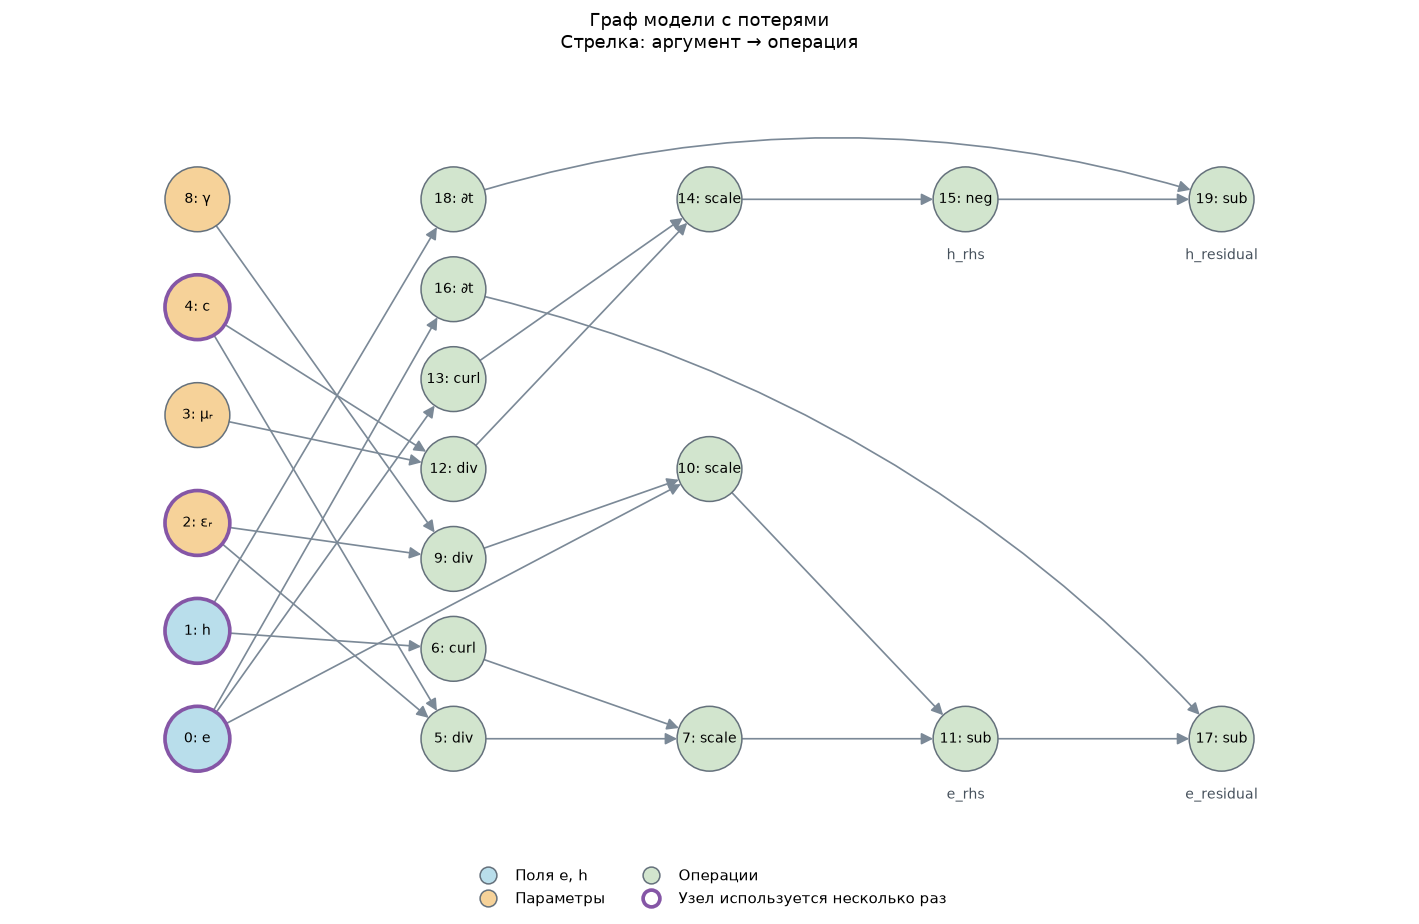

In [4]:
graph_figure = plot_graph(lossy_model)
graph_figure.savefig("results/model_graph.png", dpi=160, bbox_inches="tight")
plt.show()

На втором рисунке те же связи представлены матрицей $Z$. Строка $i$
соответствует узлу, использующему аргументы, а столбец $j$ — аргументу.
Число $Z_{ij}$ показывает, сколько раз аргумент $j$ используется узлом $i$.
Светлая ячейка соответствует нулю. Номера узлов совпадают с номерами на графе.

Матрица показывает наличие и кратность связей, но не сохраняет порядок
аргументов. Для различения выражений $a/b$ и $b/a$ вместе с ней нужен
словарь, содержащий вид операции, тип, упорядоченные входы и корни
выражений. Для $a\cdot a$ кратность связи равна двум. Эти свойства
проверяются непосредственно после рисунка.

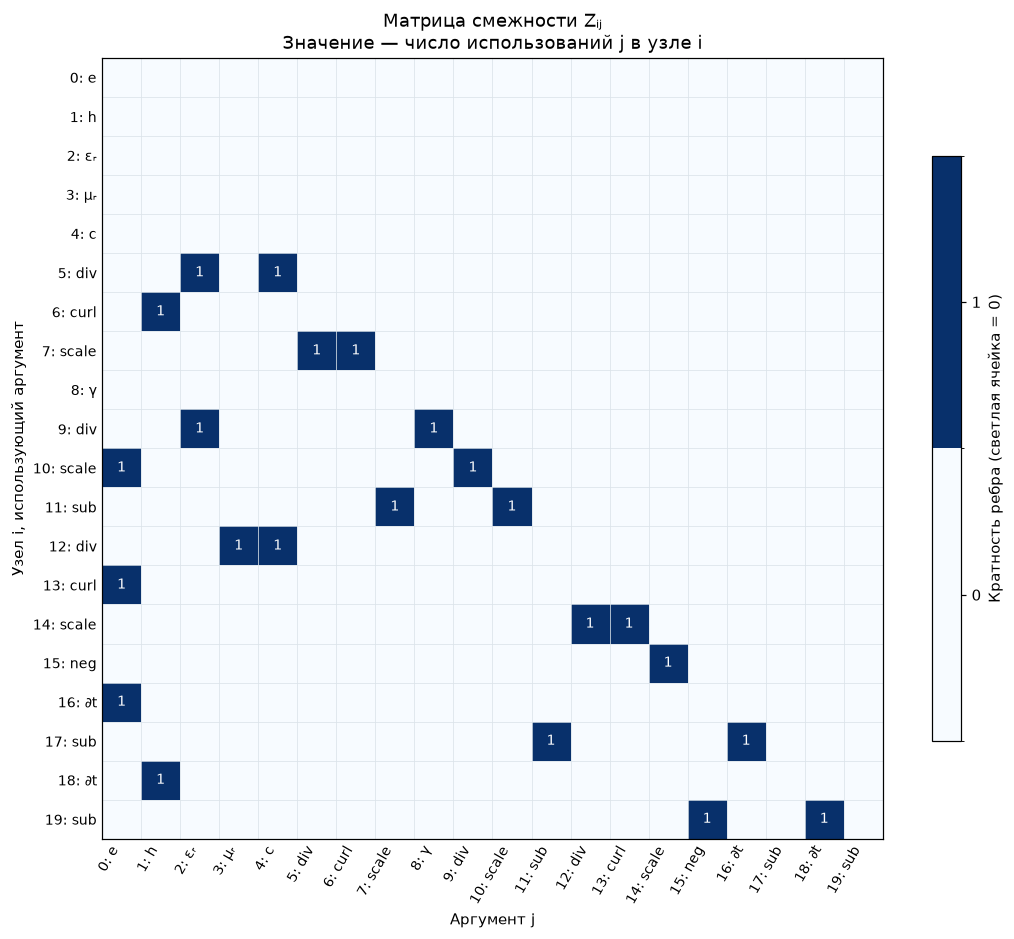

In [5]:
adjacency_figure = plot_adjacency(lossy_model)
adjacency_figure.savefig("results/model_adjacency.png", dpi=160, bbox_inches="tight")
plt.show()

In [6]:
# Повторные аргументы и порядок проверяются независимо от упрощений CAS.
demo = ExpressionDAG()
a = demo.symbol("a", kind="parameter")
b = demo.symbol("b", kind="parameter")
aa = demo.operation("mul", a, a)
ab = demo.operation("div", a, b)
demo.set_root("square", aa)
demo.set_root("ratio", ab)
roundtrip = ExpressionDAG.from_adjacency(demo.adjacency(), demo.to_dict())
assert roundtrip.nodes[aa].args == (a, a)
assert roundtrip.nodes[ab].args == (a, b)
print("Повторный вход Z[aa,a] =", roundtrip.adjacency()[aa, a])
try:
    demo.operation("curl", a)
except TypeError as error:
    print("Неверный тип корректно отклонён:", error)

Повторный вход Z[aa,a] = 2
Неверный тип корректно отклонён: Incompatible arguments for curl: ('scalar',)


### 4.2. Сравнение SymPy и SymEngine

Обе библиотеки получают одну скалярную компоненту выражения с ротором
полиномиального трёхмерного поля. Проверяются дифференцирование,
раскрытие выражения и подстановка численных значений. Сначала сравниваются
математические результаты, затем измеряется время повторных вычислений
без учёта импорта библиотек.

SymPy используется в основном символьном ядре благодаря поддержке
матриц, функций, производных и отображения формул. SymEngine служит
для сравнения общего скалярного подмножества операций. Измеренное время
характеризует этот пример; оно зависит от выражения и кеширования
и не определяет универсальный рейтинг библиотек.

In [7]:
comparison = compare_libraries()
assert comparison["equivalent"] and comparison["numeric_difference"] < 1e-14
display(
    Markdown(
        "| Библиотека | Версия | Время повторных вычислений, с |\n"
        "|---|---|---:|\n"
        f"| SymPy | {comparison['versions']['sympy']} | {comparison['sympy_seconds']:.6f} |\n"
        f"| SymEngine | {comparison['versions']['symengine']} | {comparison['symengine_seconds']:.6f} |"
    )
)
display(
    Markdown(
        f"Выполнено {comparison['repeats']} повторений. Символьные результаты эквивалентны; "
        f"разница после численной подстановки равна {comparison['numeric_difference']:.1e}."
    )
)

| Библиотека | Версия | Время повторных вычислений, с |
|---|---|---:|
| SymPy | 1.14.0 | 0.002501 |
| SymEngine | 0.14.1 | 0.000438 |

Выполнено 100 повторений. Символьные результаты эквивалентны; разница после численной подстановки равна 0.0e+00.

### 4.3. Проверка операций над векторными полями

Для проверки используются поля с заранее известными ответами.
Поле $\mathbf F=(yz,xz,xy)$ является градиентом функции $xyz$, поэтому
его ротор равен нулю. Для поля $\mathbf G=(-y,x,z^2)$ непосредственно
получаются $\nabla\times\mathbf G=(0,0,2)$ и
$\nabla\cdot\mathbf G=2z$.

Ротор возвращает векторное поле. Дивергенция характеризует локальный
баланс потока через поверхность малого объёма и возвращает скаляр.
Скалярное произведение двух векторов также возвращает число, а векторное
произведение — вектор. Для $\mathbf A=(1,2,3)$ и $\mathbf B=(4,5,6)$
ожидаются $\mathbf A\cdot\mathbf B=32$ и
$\mathbf A\times\mathbf B=(-3,6,-3)$. Следующая ячейка проверяет все ответы.

In [8]:
x, y, z = sp.symbols("x y z")
F = sp.Matrix([y * z, x * z, x * y])
G = sp.Matrix([-y, x, z**2])
curl_F = symbolic_curl(F, (x, y, z))
curl_G = symbolic_curl(G, (x, y, z))
div_G = sum(sp.diff(G[i], q) for i, q in enumerate((x, y, z)))
assert curl_F == sp.zeros(3, 1)
assert curl_G == sp.Matrix([0, 0, 2]) and div_G == 2 * z
A, B = sp.Matrix([1, 2, 3]), sp.Matrix([4, 5, 6])
assert A.dot(B) == 32 and A.cross(B) == sp.Matrix([-3, 6, -3])
display({"curl F": curl_F, "curl G": curl_G, "div G": div_G, "A·B": A.dot(B), "A×B": A.cross(B)})

{'curl F': Matrix([
 [0],
 [0],
 [0]]),
 'curl G': Matrix([
 [0],
 [0],
 [2]]),
 'div G': 2*z,
 'A·B': 32,
 'A×B': Matrix([
 [-3],
 [ 6],
 [-3]])}

## 5. Численный решатель: FDTD и схема Yee

Прямая задача состоит в вычислении полей при заданной проницаемости.
Для неё используется библиотека **fdtd** с вычислениями NumPy на CPU.
Она реализует метод конечных разностей во времени, FDTD, на сетке Yee.
Символьный граф описывает формулы, а адаптер `maxwell_fdtd.py` задаёт
конкретную геометрию и условия численного расчёта уравнений Максвелла.

Пространство разбивается на ячейки, а время — на шаги. Производные
заменяются конечными разностями. Например, разность
$(f_{i+1}-f_i)/\Delta x$ приближает производную в середине между двумя
соседними узлами. Компоненты электрического и магнитного полей разнесены
на половину пространственного и временного шага. Благодаря этому
пространственные производные и обновления по времени согласованы
со вторым порядком точности для гладкого решения.

Если после шага $n$ хранятся $\mathbf e^n$ и $\mathbf h^{n+1/2}$,
то в однородной области без источников и потерь следующий шаг имеет вид

$$
\begin{aligned}
\mathbf e^{n+1} &= \mathbf e^n+
\frac{c\Delta t}{\varepsilon_r}\operatorname{curl}_{\Delta x}\mathbf h^{n+1/2}, \\
\mathbf h^{n+3/2} &= \mathbf h^{n+1/2}-
\frac{c\Delta t}{\mu_r}\operatorname{curl}_{\Delta x}\mathbf e^{n+1}.
\end{aligned}
$$

Здесь $\operatorname{curl}_{\Delta x}$ обозначает разностный ротор.
Обновление явное: новое электрическое поле вычисляется по известному
магнитному, затем обновляется магнитное поле. На границах применяются
периодические условия, а на плоскостях возбуждения задаются значения
источников согласно исходному генератору.

Шаг времени должен удовлетворять условию устойчивости Куранта.
Для равномерной трёхмерной сетки консервативный выбор при скорости
распространения не выше c имеет вид $c\Delta t/\Delta x\leq1/\sqrt3$.
В основном опыте используются

$$
\Delta t=\frac{0.99}{\sqrt3}\frac{\Delta x}{c}
\approx9.53\cdot10^{-16}\text{ с},\qquad \Delta x=0.5\text{ мкм}.
$$

Во всём диапазоне поиска $\varepsilon_r\geq6$ и $\mu_r=1$, поэтому
скорость в среде меньше c. Выбранный временной шаг сохраняется при
подборе параметра. Точность схемы отдельно оценивается в разделе 7.

## 6. Восстановление проницаемости и оценка ошибки

Обратная задача состоит в подборе одного параметра
$\theta=(\varepsilon_r)$ при фиксированных источниках и условиях.
Для каждого пробного значения численный решатель запускается с нулевого
начального состояния. Затем рассчитанные поля сравниваются с наблюдениями.
Значение 8 служит примером до подбора, а диапазон поиска равен [6,14].

Расхождение оценивается относительной $L_2$-ошибкой. Норма означает
квадратный корень из суммы квадратов по всем выбранным компонентам,
пространственным точкам и кадрам. Для электрического поля

$$
\delta_e=\frac{\lVert\mathbf e_{\varepsilon_r}-\mathbf e_{\mathrm{obs}}\rVert_2}
{\lVert\mathbf e_{\mathrm{obs}}\rVert_2}.
$$

Аналогично определяется $\delta_h$. Деление на норму наблюдений
показывает размер расхождения относительно самого поля. Оптимизатор
минимизирует среднее двух относительных квадратов ошибок:

$$
\begin{aligned}
L(\varepsilon_r)&=\frac12\left(\delta_e^2+\delta_h^2\right), \\
\widehat\varepsilon_r&=
\underset{\varepsilon_r\in[6,14]}{\operatorname{arg\,min}}\,L(\varepsilon_r), \\
\delta_\varepsilon&=
\frac{|\widehat\varepsilon_r-\varepsilon_r^{\mathrm{ref}}|}{\varepsilon_r^{\mathrm{ref}}}.
\end{aligned}
$$

В функции L участвуют только первые четыре кадра траектории 0.
Используется ограниченный одномерный поиск
`scipy.optimize.minimize_scalar(method="bounded")`.
Для каждого пробного параметра он вызывает прямой решатель.
Скорость света, магнитная проницаемость, потери, сетка и источники
не являются переменными оптимизации.

После подбора вычисляются ошибки на последних четырёх кадрах траектории 0
и всех кадрах траектории 1. Будущие наблюдения и края сохранённой области
не подставляются в расчёт. Эталонное значение 10 используется только
для воспроизведения генератора и оценки $\delta_\varepsilon$.
До подбора требуется относительная ошибка воспроизведения меньше $10^{-8}$;
для восстановленного параметра проверяется допуск 1%.
Эти условия относятся к численному эксперименту при известных источниках.

In [9]:
arena_report, predictions = run_arena(electric, magnetic)
assert arena_report["epsilon_relative_error"] < 0.01
display(
    Markdown(
        f"Найдено **εᵣ = {arena_report['fit']['value']:.8f}** при эталоне 10. "
        f"Относительная ошибка параметра равна **{arena_report['epsilon_relative_error']:.3e}**. "
        f"Подбор потребовал {arena_report['fit']['evaluations']} вычислений функции потерь "
        f"и занял {arena_report['fit_seconds']:.2f} с."
    )
)
rows = [
    "| Проверка | Относительная ошибка e | Относительная ошибка h |",
    "|---|---:|---:|",
    f"| Воспроизведение при εᵣ = 10 | {arena_report['replay_e_error']:.3e} | {arena_report['replay_h_error']:.3e} |",
    f"| Последние четыре кадра траектории 0 | {arena_report['sample0']['e_holdout']:.3e} | {arena_report['sample0']['h_holdout']:.3e} |",
    f"| Вся траектория 1 | {arena_report['sample1']['e_holdout']:.3e} | {arena_report['sample1']['h_holdout']:.3e} |",
]
display(Markdown("\n".join(rows)))
display(
    Markdown(
        f"На поздних кадрах относительная ошибка электрического поля составляет "
        f"{100 * arena_report['sample0']['e_holdout']:.5f}%. "
        "Отложенные данные не использовались при минимизации."
    )
)

Найдено **εᵣ = 10.00000543** при эталоне 10. Относительная ошибка параметра равна **5.427e-07**. Подбор потребовал 11 вычислений функции потерь и занял 21.52 с.

| Проверка | Относительная ошибка e | Относительная ошибка h |
|---|---:|---:|
| Воспроизведение при εᵣ = 10 | 1.814e-15 | 1.781e-15 |
| Последние четыре кадра траектории 0 | 1.549e-05 | 1.526e-05 |
| Вся траектория 1 | 1.335e-05 | 1.346e-05 |

На поздних кадрах относительная ошибка электрического поля составляет 0.00155%. Отложенные данные не использовались при минимизации.

### 6.1. Функция потерь и ошибки по кадрам

На левом графике по горизонтали отложена проницаемость, а по вертикали
в логарифмическом масштабе — функция потерь L на кадрах для подбора.
Синяя линия соединяет точки предварительного просмотра функции,
а красные точки показывают значения, проверенные оптимизатором.
Малые значения около $\varepsilon_r=10$ показывают согласование расчёта
с наблюдениями при этом параметре. Конечный набор точек не доказывает
отсутствие других минимумов у произвольной задачи.

На правом графике по горизонтали указан номер кадра, а по вертикали —
относительная $L_2$-ошибка поля в логарифмическом масштабе. Сплошные линии
относятся к электрическому полю, пунктирные — к магнитному. Обозначение
траектории дано в легенде. Вертикальная линия разделяет четыре кадра
для подбора и четыре отложенных кадра траектории 0. Траектория 1 целиком
отложена. График позволяет оценить изменение ошибок со временем
и перенос найденного параметра на другое известное возбуждение.

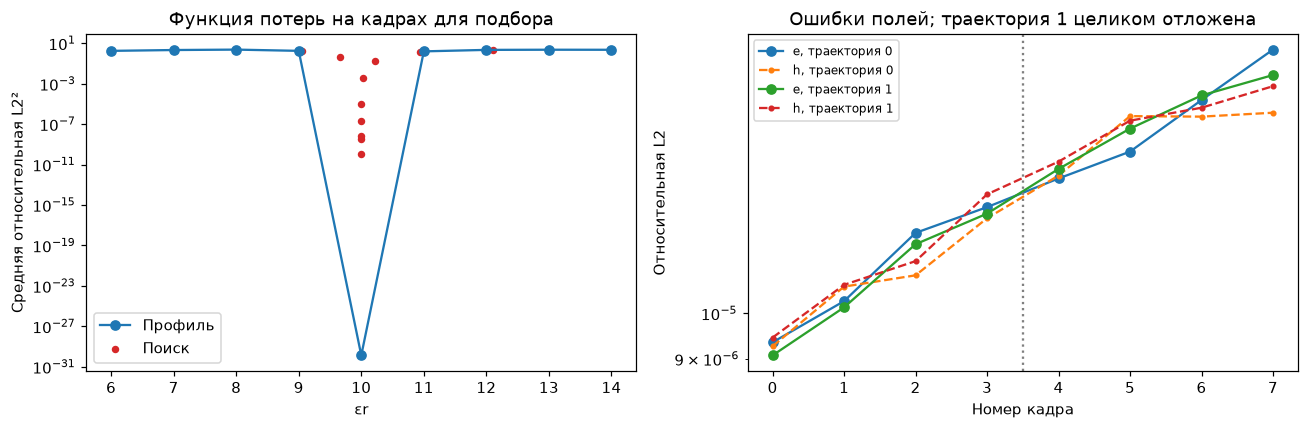

In [10]:
plot_fit(arena_report)
plt.show()

### 6.2. Пространственный срез и изменение поля во времени

На трёх цветных панелях показан компонент $e_x$ в плоскости x–y при
фиксированных z и времени последнего отложенного кадра. Координаты
подписаны в микрометрах. Слева находятся наблюдения, в центре — численное
решение, справа — знаковая разность «решение минус данные». Цвет означает
значение компонента поля, включая его знак. Первые две панели имеют
одинаковую шкалу, поэтому их можно сравнивать непосредственно.
У разности отдельная шкала, указанная рядом: интенсивный цвет здесь
может соответствовать очень малой абсолютной ошибке.

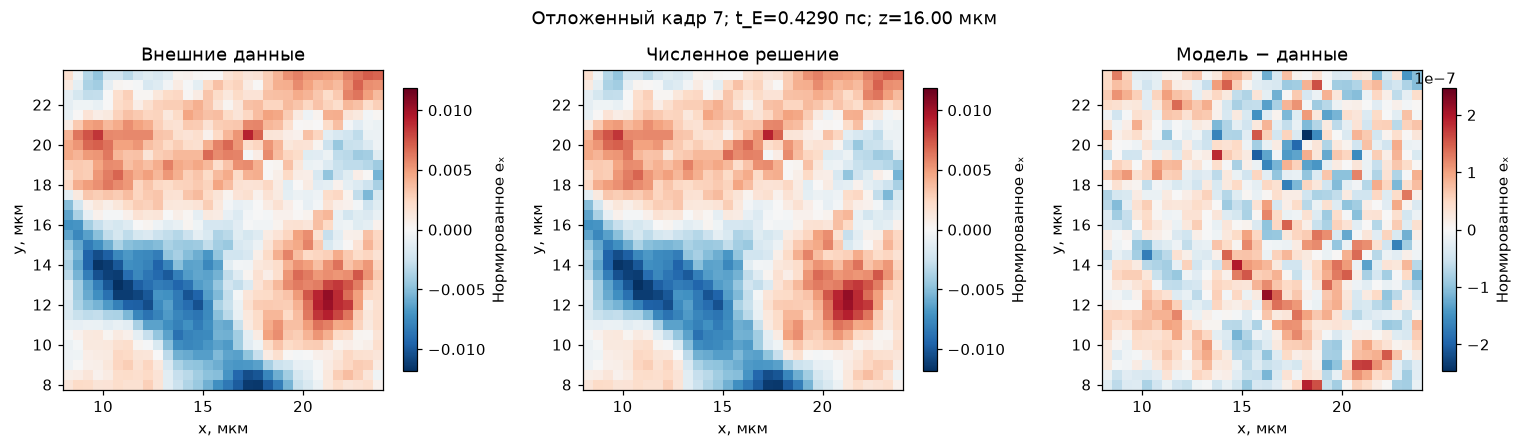

In [11]:
plot_arena_slices(electric, predictions["sample0"][0])
plt.show()

На следующих двух графиках показаны компоненты $e_x$ и $h_x$ в узлах
с индексом (16,16,16). По горизонтали отложено время в пикосекундах,
а по вертикали — значение нормированного поля. Маркеры обозначают данные,
пунктир — расчёт при $\varepsilon_r=8$, сплошная линия — расчёт после
подбора. Серая область выделяет отложенные кадры.
Совпадение сплошной линии с маркерами позволяет увидеть эффект подбора
в конкретном узле. При этом итоговая ошибка в таблице учитывает все
пространственные точки и компоненты. Координаты и времена электрического
и магнитного компонентов различаются на смещения сетки Yee.

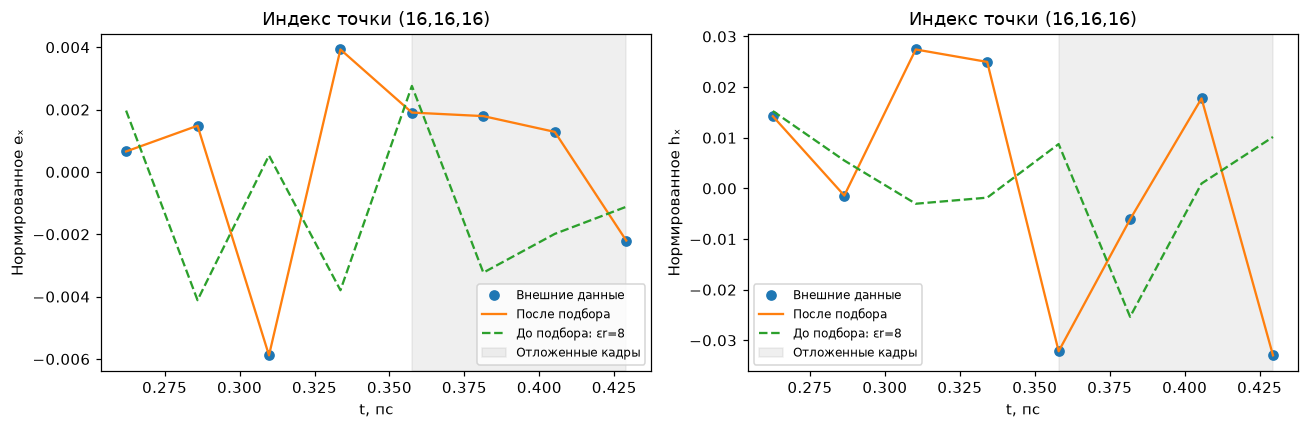

In [12]:
plot_arena_time(electric, magnetic, predictions)
plt.show()

Проницаемость восстановлена с малой ошибкой, а поля хорошо согласуются
с отложенными наблюдениями. Однако PDEArena и наш расчёт используют
одинаковую дискретизацию и известные источники. Такое совпадение
подтверждает воспроизводимость генератора и работу процедуры подбора.
Для оценки ошибки самой численной схемы необходим независимый эталон,
который рассматривается далее.

## 7. Независимое аналитическое решение и сходимость

В периодическом кубе со стороной $L=3$ см задаётся точная сумма трёх
поперечных волн. Проницаемости равны $\varepsilon_r=4$ и $\mu_r=1$,
проводимость равна нулю, а внешние источники отсутствуют.
Для каждой волны используются формулы

$$
\begin{aligned}
\mathbf e_j &= \mathbf a_j\cos(\mathbf k_j\cdot\mathbf r-\omega_jt), \\
\mathbf h_j &= \frac{c}{\omega_j}(\mathbf k_j\times\mathbf a_j)
\cos(\mathbf k_j\cdot\mathbf r-\omega_jt), \\
\omega_j &= \frac{c\lVert\mathbf k_j\rVert}{\sqrt{\varepsilon_r}}, &
\mathbf k_j\cdot\mathbf a_j&=0.
\end{aligned}
$$

Полные поля равны суммам по трём волнам. Волновые векторы имеют вид
$\mathbf k_j=(2\pi/L)\mathbf m_j$, где
$\mathbf m_j=(1,1,0),(0,1,1),(1,0,1)$. Направления поляризации равны
$(1,-1,0),(0,1,-1),(1,0,-1)$ и нормируются до единичной длины.
Амплитуды равны 1, 0.7 и 0.4. Поле меняется вдоль всех трёх координат,
а частота каждой волны составляет около 7.07 ГГц.

Точные поля вычисляются по формулам в собственных координатах и в собственные
моменты каждого компонента Yee. Численное решение получает эти значения
только как начальное состояние и далее развивается самостоятельно.
Сравниваются сетки с 12, 24 и 48 уникальными ячейками по каждой оси.
В массиве присутствует дополнительная дублирующая периодическая плоскость,
которая исключается из норм ошибок.

В этом опыте $c\Delta t/\Delta x=0.4$. При удвоении числа ячеек оба шага
уменьшаются вдвое, а сравнение выполняется в одинаковый момент времени.
В таблице приведены относительные ошибки полей и наблюдаемый порядок
сходимости между соседними сетками:

$$
p=\frac{\ln(\delta_{\mathrm{пред}}/\delta_{\mathrm{тек}})}
{\ln(n_{\mathrm{тек}}/n_{\mathrm{пред}})}.
$$

Для схемы второго порядка ожидается $p\approx2$, то есть уменьшение
ошибки примерно в четыре раза при таком уточнении. Для первой сетки
порядок не вычисляется, поскольку предыдущей сетки нет.

In [13]:
analytic_report = run_analytic()
convergence = analytic_report["convergence"]
rows = [
    r"| Сетка | $\Delta x$, мм | $\Delta t$, пс | $\delta_e$ | $\delta_h$ | $p_e$ | $p_h$ |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for index, row in enumerate(convergence):
    orders = []
    for field in ("electric", "magnetic"):
        if index == 0:
            orders.append("—")
        else:
            previous = convergence[index - 1]
            order = np.log(previous[f"{field}_relative_l2"] / row[f"{field}_relative_l2"]) / np.log(
                row["n"] / previous["n"]
            )
            orders.append(f"{order:.2f}")
    rows.append(
        f"| {row['n']}³ | {30 / row['n']:.3f} | {row['dt_s'] * 1e12:.3f} | "
        f"{row['electric_relative_l2']:.3e} | {row['magnetic_relative_l2']:.3e} | "
        f"{orders[0]} | {orders[1]} |"
    )
convergence_table = "\n".join(rows)
display(Markdown(convergence_table))
Path("results/convergence_table.md").write_text(convergence_table + "\n")
first, finest = convergence[0], convergence[-1]
display(
    Markdown(
        f"Время сравнения e: **{finest['time_s'] * 1e12:.2f} пс**; "
        "поле h сравнивается со своим эталоном на полшага позже. "
        f"При уточнении от {first['n']}³ до {finest['n']}³ ошибка e уменьшается "
        f"в **{first['electric_relative_l2'] / finest['electric_relative_l2']:.1f} раза**, "
        f"h — в **{first['magnetic_relative_l2'] / finest['magnetic_relative_l2']:.1f} раза**."
    )
)

| Сетка | $\Delta x$, мм | $\Delta t$, пс | $\delta_e$ | $\delta_h$ | $p_e$ | $p_h$ |
|---|---:|---:|---:|---:|---:|---:|
| 12³ | 2.500 | 3.336 | 1.790e-02 | 1.940e-02 | — | — |
| 24³ | 1.250 | 1.668 | 4.574e-03 | 4.761e-03 | 1.97 | 2.03 |
| 48³ | 0.625 | 0.834 | 1.156e-03 | 1.179e-03 | 1.98 | 2.01 |

Время сравнения e: **40.03 пс**; поле h сравнивается со своим эталоном на полшага позже. При уточнении от 12³ до 48³ ошибка e уменьшается в **15.5 раза**, h — в **16.5 раза**.

На графике по горизонтали отложено число ячеек по оси, а по вертикали —
относительная ошибка. Обе оси имеют логарифмический масштаб.
Две сплошные линии соответствуют электрическому и магнитному полям,
а пунктир показывает ожидаемую зависимость ошибки от квадрата шага.
Близкие наклоны линий указывают на второй порядок сходимости.
В таблице ошибка электрического поля уменьшается примерно с 1.79%
до 0.46% и затем до 0.12%, что согласуется с этим выводом.

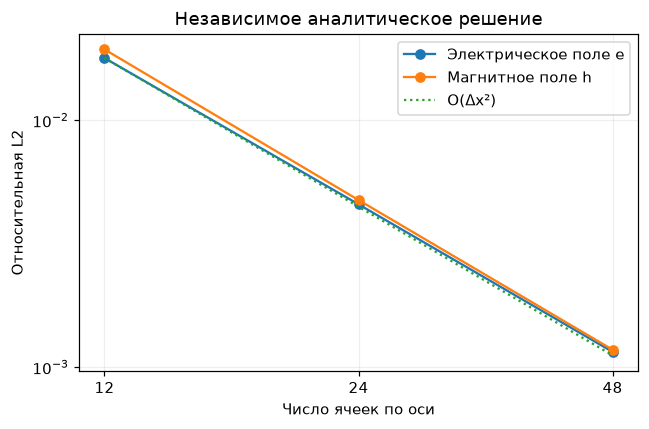

In [14]:
plot_convergence(analytic_report)
plt.show()

Дополнительно контролируются дискретные дивергенции и изменение оценки
энергии. В точной периодической волне без источников дивергенции равны
нулю. Обычная сумма энергий e и h вычисляется на разнесённых временных
уровнях, поэтому оценивается уменьшение её дрейфа при уточнении сетки.

На сетке 24³ также решается обратная задача по одному точному состоянию.
Начальные поля фиксированы и не меняются при пробных проницаемостях.
Полученный параметр проверяется по состоянию при удвоенном времени,
которое не участвовало в подборе. Это отделяет ошибку восстановления
параметра от совпадения с тем же дискретным генератором.

In [15]:
display(
    Markdown(
        f"**Контроль на сетке {finest['n']}³:** безразмерные дивергенции "
        f"e/h — {finest['div_e_dimensionless']:.2e} / {finest['div_h_dimensionless']:.2e}; "
        f"относительный дрейф энергии — {finest['relative_energy_drift']:.2e}.\n\n"
        "**Подбор по аналитическому эталону (сетка 24³):** "
        f"εᵣ = {analytic_report['continuum_fit']['value']:.6f} при эталоне 4, "
        f"ошибка параметра {analytic_report['epsilon_relative_error']:.2%}. "
        "Ошибки полей на отложенном удвоенном времени: "
        f"e — {analytic_report['later_e_error']:.3e}, h — {analytic_report['later_h_error']:.3e}.\n\n"
        "Полные метрики и история подбора сохраняются в `results/experiment.json`."
    )
)
assert analytic_report["epsilon_relative_error"] < 0.02

**Контроль на сетке 48³:** безразмерные дивергенции e/h — 2.29e-13 / 1.55e-13; относительный дрейф энергии — 4.31e-07.

**Подбор по аналитическому эталону (сетка 24³):** εᵣ = 3.984073 при эталоне 4, ошибка параметра 0.40%. Ошибки полей на отложенном удвоенном времени: e — 1.535e-03, h — 2.994e-03.

Полные метрики и история подбора сохраняются в `results/experiment.json`.

В этом опыте восстановленная проницаемость составляет около 3.984
при точном значении 4, а относительная ошибка параметра — около 0.40%.
Разностная схема имеет небольшую погрешность фазовой скорости, и подбор
частично компенсирует её изменением параметра. Поэтому почти точное
восстановление по PDEArena не означает столь же малую ошибку относительно
непрерывного решения. Сходимость при уточнении сетки даёт отдельное
подтверждение корректного поведения численного метода.

## 8. Диагностика полей СВЧ-платы из EMVal

Для независимой геометрии выбраны порт с индексом 0 и частота с индексом
50, около 10.5 ГГц. Координаты точек заданы в метрах, электрическое поле —
в В/м, магнитное — в А/м. Диэлектрическое ядро выбранной платы имеет
$\varepsilon_r=3.55$, тангенс потерь $\tan\delta=0.0027$ и толщину
203.2 мкм. Проводимость меди равна $5.96\cdot10^7$ См/м.
Эти свойства берутся из `design.json` и не подбираются по полям.

Комплексная амплитуда описывает величину колебаний и фазу. Для одной
частоты гармоническое поле можно записать как

$$
\mathbf E(\mathbf r,t)=\operatorname{Re}
\left[\widehat{\mathbf E}(\mathbf r)e^{s i\omega t}\right],
\qquad \omega=2\pi f,\quad s\in\{-1,+1\}.
$$

Знак временной конвенции не указан в доступных метаданных, поэтому
диагностика выполняется для обоих знаков. Для рисунка выбирается $s=+1$.
Это реконструкция установившихся колебаний по комплексной амплитуде.
Исходный решатель и внешние граничные условия также не документированы
достаточно полно для воспроизведения расчёта платы.

Внутри однородных областей вне портов проверяются уравнения

$$
\begin{aligned}
\nabla\times\widehat{\mathbf E}&=-s i\omega\mu_0\widehat{\mathbf H}, \\
\nabla\times\widehat{\mathbf H}&=
(\sigma_{\mathrm{eff}}+s i\omega\varepsilon_0\varepsilon_r)\widehat{\mathbf E}, \\
\sigma_{\mathrm{eff}}&=\omega\varepsilon_0\varepsilon_r\tan\delta.
\end{aligned}
$$

Эквивалентная проводимость описывает потери на выбранной частоте.
Она не определяет полный закон дисперсии материала.
Сравниваются известные свойства диэлектрика и предположение, что
вся область заполнена воздухом. Точки в металле, на границах материалов
и вблизи портов исключаются из дифференцирования.

Для оценки производных по нерегулярным точкам используются локальные
трёхмерные полиномы второй степени с весами. Проверяются окрестности
из 40, 60 и 100 соседей той же среды. Согласованность левой и правой
частей уравнения оценивается нормированной невязкой

$$
\mathcal R=\frac{\lVert A-B\rVert_2}{\lVert A\rVert_2+\lVert B\rVert_2},
$$

где A и B обозначают две части проверяемого уравнения. Невязка лежит
между нулём и единицей; нулевое значение соответствует совпадению.
На тех же координатах отдельно проверяется дифференцирование гладкой
точной волны, чтобы оценить работу алгоритма на контролируемом примере.

В таблице k обозначает число соседей, а `cond` — медианное число
обусловленности матрицы локального приближения. Столбец ошибки приближения
E характеризует качество самого полинома. Остальные столбцы содержат
невязки уравнений Фарадея и Ампера при выбранных свойствах материала,
при предположении воздуха и на гладкой контрольной волне.
Для компактности таблица показывает конвенцию $s=+1$; оба знака
сохраняются в итоговом отчёте.

In [16]:
emval_report, cloud = run_emval(paths["emval.h5"])
print(
    "Точки:",
    cloud.points.shape,
    "; поле:",
    cloud.electric.shape,
    "; частота:",
    cloud.frequency,
    "Hz",
)
print("Диапазон x/y/z, мм:", np.ptp(cloud.points, axis=0) * 1e3)
rows = [
    "| k | Область | cond | Ошибка приближения E | Фарадей | Ампер, материал | Ампер, воздух | Ампер, контроль |",
    "|---|---|---|---|---|---|---|---|",
]
for k in ("40", "60", "100"):
    for region in ("air", "core"):
        r = emval_report["diagnostics"][k][region]
        p = r["exp_+1iwt"]
        control = emval_report["smooth_wave_control"][k][region]["ampere"]
        rows.append(
            f"| {k} | {region} | {r['median_condition']:.2f} | {r['median_E_fit_residual']:.3f} | {p['faraday']:.3f} | {p['ampere_material']:.3f} | {p['ampere_air_assumption']:.3f} | {control:.4f} |"
        )
display(Markdown("\n".join(rows)))
print("Оба знака и все диагностические метрики сохраняются в results/experiment.json")

Точки: (10000, 3) ; поле: (10000, 3) ; частота: 10499999744.0 Hz
Диапазон x/y/z, мм: [15.12920577 11.74747664 10.90944884]


| k | Область | cond | Ошибка приближения E | Фарадей | Ампер, материал | Ампер, воздух | Ампер, контроль |
|---|---|---|---|---|---|---|---|
| 40 | air | 7.23 | 0.322 | 0.775 | 0.863 | 0.863 | 0.0021 |
| 40 | core | 11.31 | 0.180 | 0.851 | 0.805 | 0.932 | 0.0016 |
| 60 | air | 6.78 | 0.397 | 0.700 | 0.826 | 0.826 | 0.0025 |
| 60 | core | 10.30 | 0.235 | 0.841 | 0.811 | 0.934 | 0.0022 |
| 100 | air | 6.61 | 0.483 | 0.646 | 0.807 | 0.807 | 0.0033 |
| 100 | core | 9.73 | 0.307 | 0.818 | 0.818 | 0.937 | 0.0035 |

Оба знака и все диагностические метрики сохраняются в results/experiment.json


На левом рисунке показано расположение точек EMVal в трёхмерном
пространстве вокруг и внутри платы. Координаты подписаны в миллиметрах.
Для читаемости отображается каждая десятая точка. Цвет показывает
десятичный логарифм модуля комплексной амплитуды электрического поля,
отнесённого к 1 В/м. Логарифмическая шкала позволяет одновременно увидеть
области слабого и сильного поля; цвет не обозначает его направление.

Справа показаны три компоненты электрического поля в одной выбранной
точке в течение двух периодов. По горизонтали отложено время в
наносекундах, а по вертикали — поле в В/м. Кривые получены из одной
комплексной амплитуды при $s=+1$. Они иллюстрируют переход от частотного
представления к гармоническим колебаниям и не являются отдельной
проверкой точности решателя.

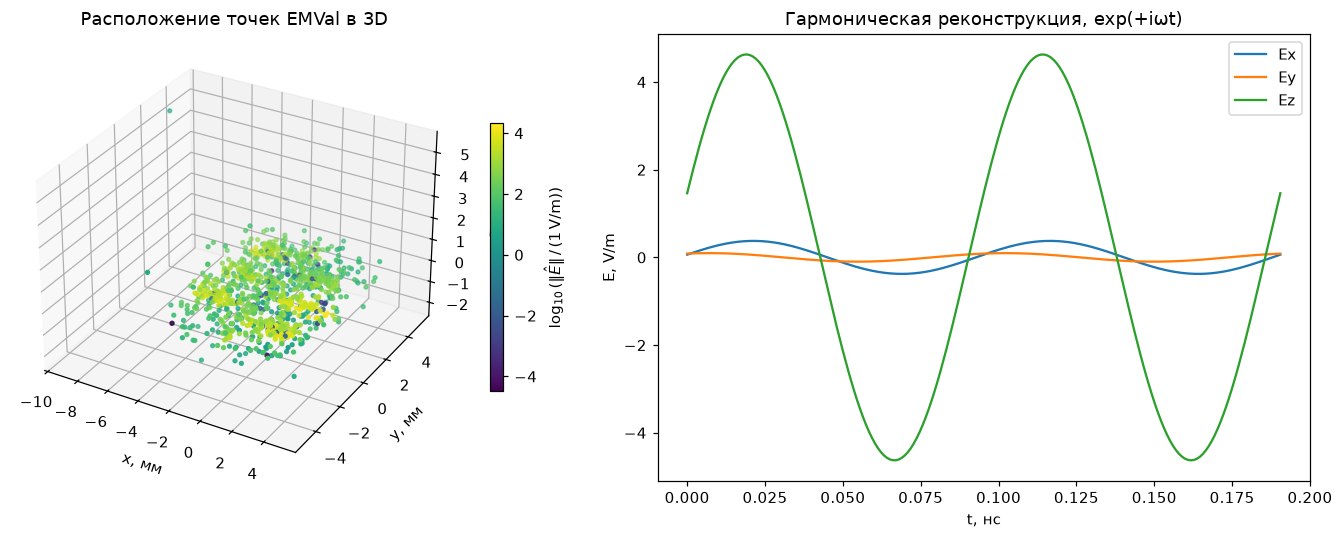

In [17]:
plot_emval(cloud)
plt.show()

Невязки на полях EMVal велики и заметно зависят от размера окрестности.
Использование свойств диэлектрика уменьшает некоторые из них по сравнению
с предположением воздуха, однако их величина остаётся слишком большой
для подтверждения модели. Ошибка локального полиномиального приближения
также значительна, что указывает на недостаточную точность восстановления
производных сложного ближнего поля выбранным способом.

На гладкой контрольной волне ошибки меньше, но этот результат не задаёт
верхнюю границу ошибки для поля с резкими пространственными изменениями.
Поэтому большие невязки не позволяют заключить, что исходные данные
нарушают уравнения Максвелла. Для строгой проверки нужны сведения
о сетке исходного расчёта, внешних границах и фазовой конвенции,
а также более точный способ оценки производных или интегральная форма
уравнений. EMVal в этой работе используется для диагностики;
полный расчёт платы и восстановление её параметров не выполняются.

## 9. Выводы

Уравнения Максвелла представлены как типизированные символьные выражения.
Их структура сохраняется в графе, словаре и матрице с метаданными
и восстанавливается с сохранением порядка и повторений аргументов.
Проверка на известных примерах подтверждает корректность используемых
векторных операций. SymPy и SymEngine дают согласованные результаты
для выбранного общего набора операций.

Солвер `fdtd` по схеме Yee связан с отдельной процедурой подбора одного
параметра. На синтетических данных PDEArena восстановлено значение
$\varepsilon_r\approx10.0000054$ при эталоне 10. Относительная ошибка
электрического поля на поздних кадрах составляет около $1.55\cdot10^{-5}$,
а на второй траектории — около $1.33\cdot10^{-5}$. Эти результаты
характеризуют задачу с известными источниками и той же дискретизацией,
которая использовалась при генерации данных.

Независимое аналитическое решение подтверждает близкий ко второму
порядок сходимости при совместном уточнении пространственного
и временного шагов. Ошибка электрического поля на сетке 48³ составляет
около 0.12%. Подбор по непрерывному эталону даёт ошибку параметра около
0.40%, показывая влияние дискретизации на обратную задачу.

На независимых полях EMVal выбранная локальная диагностика не позволила
подтвердить точность модели платы. Этот результат определяет ограничение
способа восстановления производных и доступных метаданных.

Символьное описание, параметры, данные и численный расчёт разделены
по модулям. Добавление потерь через композицию существующих операций
даёт основу для построения более сложных моделей. Численный адаптер
при этом реализует выбранный класс уравнений Максвелла.
Дальнейшее исследование может оценивать устойчивость подбора при шуме
в наблюдениях и при неполном знании источников.

Следующая ячейка сохраняет рассчитанные метрики и контрольные суммы кода.
Полный повторный запуск выполняется командой
`python scripts/run_notebook.py`, а автоматические проверки —
командой `python -m pytest -q`.

In [18]:
report = {
    "arena": arena_report,
    "analytic": analytic_report,
    "emval": emval_report,
    "symbolic_comparison": comparison,
    "notebook_seconds": time.perf_counter() - started_notebook,
}
report_path = save_report(report)
print("Отчёт:", report_path.relative_to(Path.cwd()))
print("Полный расчёт notebook, с:", round(report["notebook_seconds"], 2))
print("Данные и результаты пересчитаны в текущем ядре; см. ограничения выше.")

Отчёт: results/experiment.json
Полный расчёт notebook, с: 52.96
Данные и результаты пересчитаны в текущем ядре; см. ограничения выше.
